<a href="https://colab.research.google.com/github/yaten01/MNIST-dataset-preprocessing-/blob/main/mnist_practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from urllib.request import urlretrieve
from pathlib import Path
import cv2

In [2]:
url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
file_name = 'mnist.npz'

urlretrieve(url, file_name)
with np.load(file_name) as data:
    x_train = data['x_train']
    y_train = data['y_train']
    x_test = data['x_test']
    y_test = data['y_test']

print(f"training images shape: {x_train.shape}")
print(f"training labels shape: {y_train.shape}")
print(f"testing images shape: {x_test.shape}")
print(f"testing labels shape: {y_test.shape}")

training images shape: (60000, 28, 28)
training labels shape: (60000,)
testing images shape: (10000, 28, 28)
testing labels shape: (10000,)


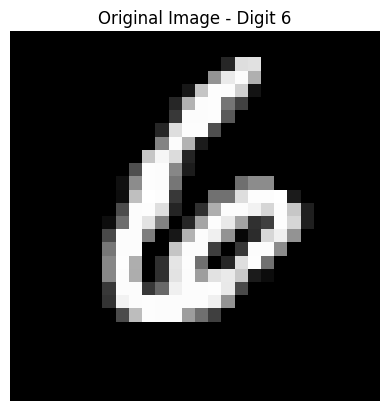

In [3]:
img = x_train[13]

plt.imshow(img, cmap="gray")
plt.title("Original Image - Digit 6")
plt.axis("off")
plt.show()

In [4]:
img = x_train[13]

print("Minimum pixel:", img.min())
print("Maximum pixel:", img.max())
print("Average pixel:", img.mean())

Minimum pixel: 0
Maximum pixel: 255
Average pixel: 36.27933673469388


In [5]:
counts = np.bincount(y_train)

for digit in range(10):
    print("Digit", digit, ":", counts[digit], "images")

Digit 0 : 5923 images
Digit 1 : 6742 images
Digit 2 : 5958 images
Digit 3 : 6131 images
Digit 4 : 5842 images
Digit 5 : 5421 images
Digit 6 : 5918 images
Digit 7 : 6265 images
Digit 8 : 5851 images
Digit 9 : 5949 images


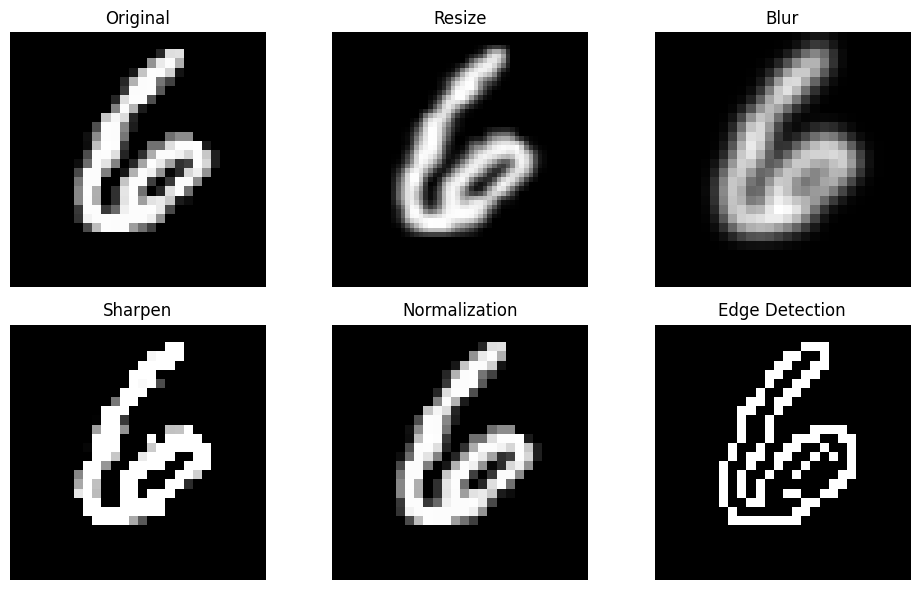

In [7]:
resized = cv2.resize(img, (56, 56))

blurred = cv2.GaussianBlur(img, (5, 5), 0)

kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(img, -1, kernel)

normalized = img.astype(float) / 255.0

edges = cv2.Canny(img, 50, 150)

images = [img, resized, blurred, sharpened, normalized, edges]

titles = [
    "Original",
    "Resize",
    "Blur",
    "Sharpen",
    "Normalization",
    "Edge Detection"
]

plt.figure(figsize=(10, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    if i == 4:
        plt.imshow(images[i], cmap="gray", vmin=0, vmax=1)
    else:
        plt.imshow(images[i], cmap="gray")

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()